In [1]:
import pandas as pd

df = pd.read_csv("../data/raw_data.csv")
df.head()




,text,brand,date,sentiment,user_id,location,user_followers,likes,shares,comments,...,platform,campaign_id,product_mentioned,is_response,time,day_of_week,is_holiday,sentiment_confidence,emotion_categories,sentiment_aspects
0,Amazon is setting the standard again.,Amazon,04/01/2025,positive,user_0,Germany,1411,63,137,54,...,Facebook,CAMP003,Product B,False,11:54:00,Tuesday,True,0.74,Neutral,"Quality, Delivery"
1,No strong feelings about Microsoft either way.,Microsoft,20/05/2025,neutral,user_1,Germany,3754,222,200,57,...,LinkedIn,NaN,Product B,False,02:33:00,Tuesday,True,0.57,Joy,"Delivery, Quality, Service"
2,Apple announced a new product today.,Apple,28/06/2025,neutral,user_2,UK,2748,333,17,75,...,Instagram,NaN,Product A,True,12:26:00,Tuesday,False,0.69,"Anger, Sadness","Service, Price"
3,Nike's product broke after a week.,Nike,27/01/2025,negative,user_3,USA,1331,199,3,92,...,Facebook,NaN,Product C,True,20:39:00,Thursday,True,0.88,"Surprise, Sadness",Service
4,Tesla announced a new product today.,Tesla,04/10/2024,neutral,user_4,UK,8565,319,113,7,...,Instagram,NaN,NaN,False,20:20:00,Wednesday,True,0.60,Neutral,"Quality, Price"


In [2]:
df = df[["text", "brand", "date", "location"]]
df.head()


,text,brand,date,location
0,Amazon is setting the standard again.,Amazon,04/01/2025,Germany
1,No strong feelings about Microsoft either way.,Microsoft,20/05/2025,Germany
2,Apple announced a new product today.,Apple,28/06/2025,UK
3,Nike's product broke after a week.,Nike,27/01/2025,USA
4,Tesla announced a new product today.,Tesla,04/10/2024,UK


In [3]:
df.shape


(600, 4)

In [4]:
df.to_csv("../data/basic_data.csv", index=False)


In [2]:
import re
import pandas as pd
import nltk
from nltk.corpus import stopwords

df = pd.read_csv("../data/basic_data.csv")

stop_words = set(stopwords.words("english"))
negation_words = {"no", "not", "nor", "never"}
stop_words = stop_words - negation_words

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+", "", text)
    text = re.sub(r"[^a-z\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    text = " ".join(word for word in text.split() if word not in stop_words)
    return text

df["clean_text"] = df["text"].apply(clean_text)

df[["text", "clean_text"]].head()


,text,clean_text
0,Amazon is setting the standard again.,amazon setting standard
1,No strong feelings about Microsoft either way.,no strong feelings microsoft either way
2,Apple announced a new product today.,apple announced new product today
3,Nike's product broke after a week.,nikes product broke week
4,Tesla announced a new product today.,tesla announced new product today


In [3]:
import pandas as pd
df.to_csv("../data/clean_text_data_FINAL.csv", index=False)
pd.read_csv("../data/clean_text_data_FINAL.csv").head()


,text,brand,date,location,clean_text
0,Amazon is setting the standard again.,Amazon,04-01-2025,Germany,amazon setting standard
1,No strong feelings about Microsoft either way.,Microsoft,20-05-2025,Germany,no strong feelings microsoft either way
2,Apple announced a new product today.,Apple,28-06-2025,UK,apple announced new product today
3,Nike's product broke after a week.,Nike,27-01-2025,USA,nikes product broke week
4,Tesla announced a new product today.,Tesla,04-10-2024,UK,tesla announced new product today


In [4]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk
nltk.download("vader_lexicon")
sia = SentimentIntensityAnalyzer()
df["sentiment_score"] = df["clean_text"].apply(
    lambda x: sia.polarity_scores(x)["compound"]
)
def label_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

df["sentiment"] = df["sentiment_score"].apply(label_sentiment)



[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\rssto\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [5]:
df.to_csv("../data/final_sentiment_data.csv", index=False)


In [6]:
sentiment_counts = df["sentiment"].value_counts()
sentiment_counts


sentiment
Positive    301
Neutral     173
Negative    126
Name: count, dtype: int64

In [7]:
sentiment_percent = df["sentiment"].value_counts(normalize=True) * 100
sentiment_percent


sentiment
Positive    50.166667
Neutral     28.833333
Negative    21.000000
Name: proportion, dtype: float64

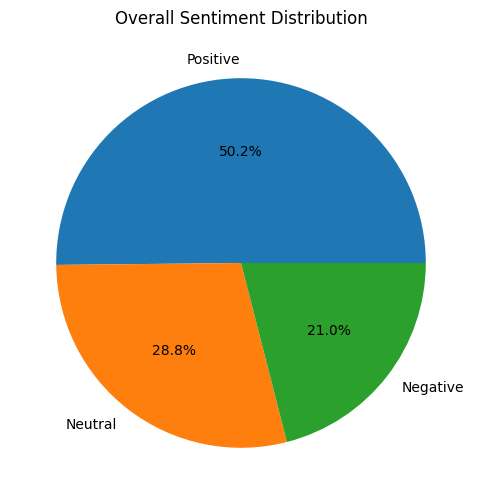

In [8]:
import matplotlib.pyplot as plt

sentiment_percent.plot(kind="pie", autopct="%1.1f%%", figsize=(6,6))
plt.title("Overall Sentiment Distribution")
plt.ylabel("")
plt.savefig("../visualization/sentiment_distribution.png")
plt.show()


In [9]:
df["date"] = pd.to_datetime(df["date"], format="%d-%m-%Y", errors="coerce")
df["date"].head()


0   2025-01-04
1   2025-05-20
2   2025-06-28
3   2025-01-27
4   2024-10-04
Name: date, dtype: datetime64[us]

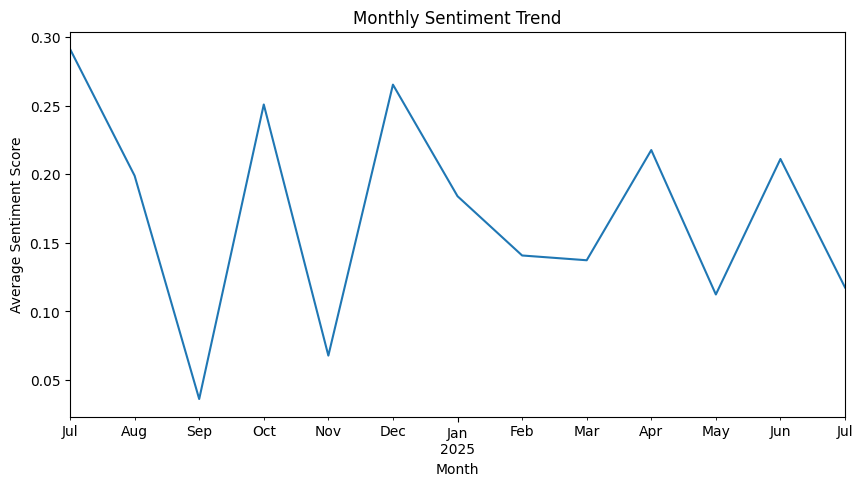

In [10]:
trend_monthly = df.groupby(df["date"].dt.to_period("M"))["sentiment_score"].mean()
trend_monthly
import matplotlib.pyplot as plt

trend_monthly.plot(figsize=(10,5))
plt.title("Monthly Sentiment Trend")
plt.xlabel("Month")
plt.ylabel("Average Sentiment Score")
plt.savefig("../visualization/sentiment_trend.png")
plt.show()


In [18]:
positive_text = " ".join(df[df["sentiment"] == "Positive"]["clean_text"])
negative_text = " ".join(df[df["sentiment"] == "Negative"]["clean_text"])
remove_words = {
    "product", "products",
    "amazon", "microsoft", "apple","google"
    "nike", "tesla", "cocacola","remains","intel","dell","lenovo","sony","facebook"
    "adidas", "samsung","nike","apple","linkedin","no","latest","release","week","either","way","time","using","experience"
}
positive_words = [
    word for word in positive_text.split()
    if word not in remove_words
]

negative_words = [
    word for word in negative_text.split()
    if word not in remove_words
]
def normalize_word(word):
    if word.endswith("s"):
        return word[:-1]
    return word



In [19]:
from collections import Counter

positive_common = Counter(positive_words).most_common(10)
negative_common = Counter(negative_words).most_common(3)
print("The most common words in positive posts: ",positive_common)
print("The most common words in negative posts: ",negative_common)



The most common words in positive posts:  [('new', 50), ('amazing', 48), ('strong', 46), ('feelings', 46), ('love', 45), ('really', 40), ('impressed', 40), ('service', 40), ('popular', 39), ('choice', 39)]
The most common words in negative posts:  [('terrible', 42), ('broke', 41), ('disappointed', 41)]


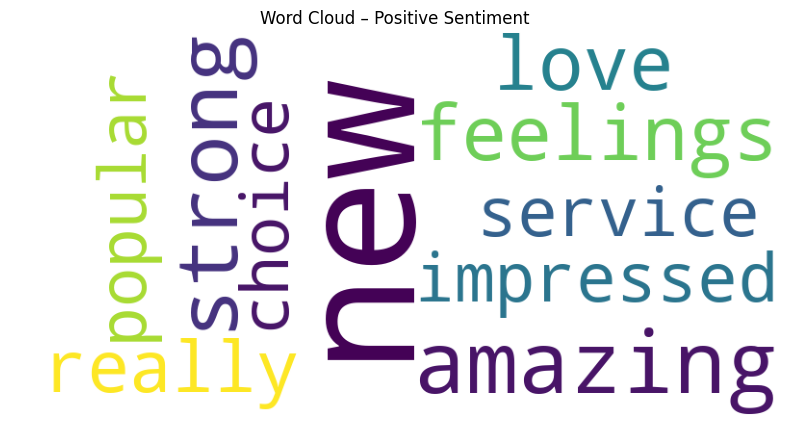

In [20]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
positive_freq = dict(positive_common)

wc_positive = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate_from_frequencies(positive_freq)

plt.figure(figsize=(10,5))
plt.imshow(wc_positive)
plt.axis("off")
plt.title("Word Cloud – Positive Sentiment")
plt.savefig("../visualization/positive_wordcloud.png")
plt.show()


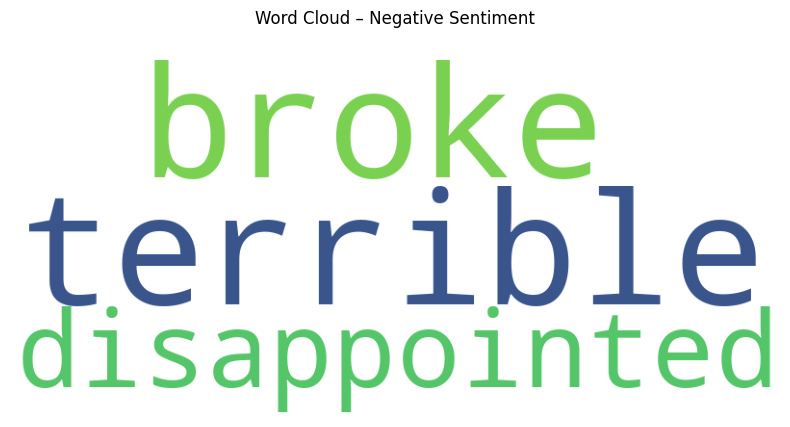

In [21]:
negative_freq = dict(negative_common)

wc_negative = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate_from_frequencies(negative_freq)

plt.figure(figsize=(10,5))
plt.imshow(wc_negative)
plt.axis("off")
plt.title("Word Cloud – Negative Sentiment")

plt.savefig("../visualization/negative_wordcloud.png")
plt.show()


In [22]:
brand_sentiment = df.groupby(["brand", "sentiment"]).size().unstack(fill_value=0)
brand_sentiment.head()


sentiment,Negative,Neutral,Positive
brand,,,
Adidas,9,13,26
Airbnb,1,4,5
Amazon,15,0,38
Apple,12,14,18
BMW,1,4,2


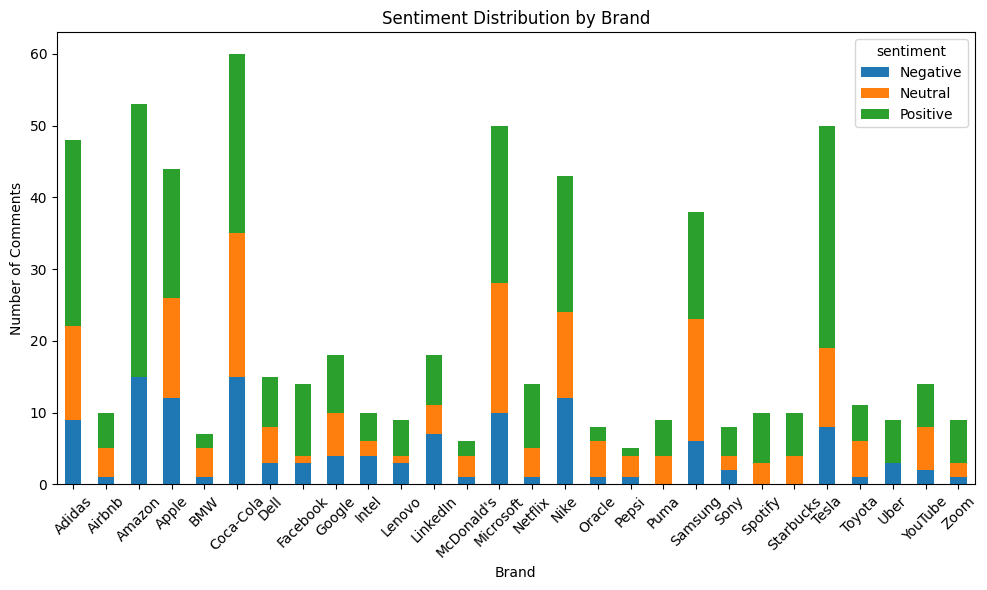

In [23]:
brand_sentiment.plot(
    kind="bar",
    stacked=True,
    figsize=(10,6)
)

plt.title("Sentiment Distribution by Brand")
plt.xlabel("Brand")
plt.ylabel("Number of Comments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()




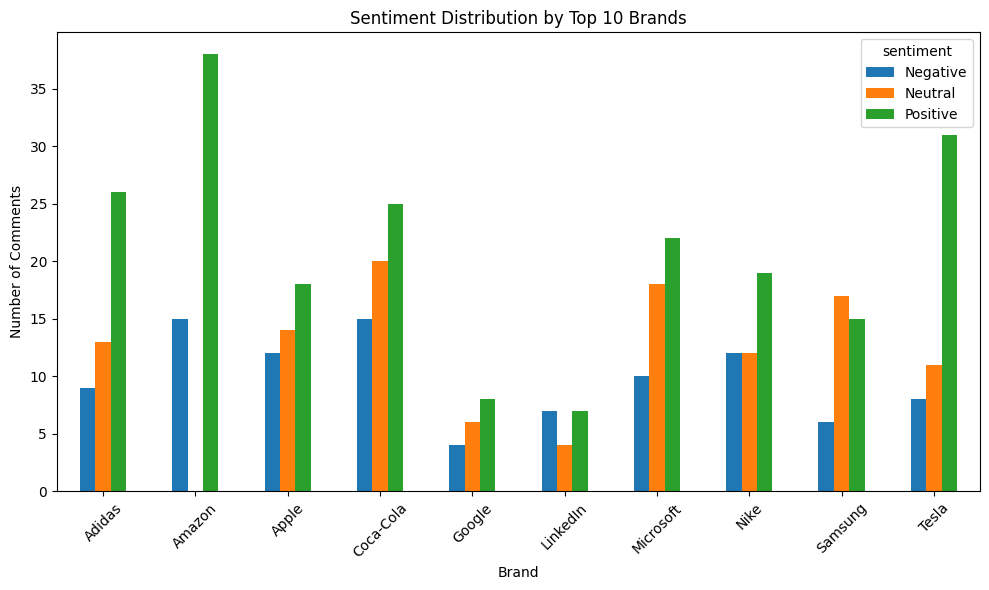

In [24]:
top_brands = df["brand"].value_counts().head(10).index
filtered_df = df[df["brand"].isin(top_brands)]

brand_sentiment = (
    filtered_df
    .groupby(["brand", "sentiment"])
    .size()
    .unstack(fill_value=0)
)

brand_sentiment.plot(kind="bar", figsize=(10,6))
plt.title("Sentiment Distribution by Top 10 Brands")
plt.xlabel("Brand")
plt.ylabel("Number of Comments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
